# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
import os

for root, dirs, files in os.walk(".."):
    dirs[:] = [d for d in dirs if d != ".venv"]
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

../week04/gapminder.csv
../data/global_energy_mix.csv
../data/netflix_catalogue.csv
../data/co2_emissions.csv
../data/world_development.csv
../data/airbnb_london.csv
../data/world_happiness_2023.csv
../data/gapminder.csv


In [ ]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


In [4]:
import pandas as pd
import numpy as np
import plotly.express as px

# Load the Airbnb London dataset
df = pd.read_csv("../data/airbnb_london.csv")

# Display the first five rows
df.head()

,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
0,Hammersmith,Entire home/apt,148.55,6,158,302,3.75
1,Kensington and Chelsea,Private room,393.56,29,46,323,2.56
2,Camden,Entire home/apt,197.64,19,242,291,2.52
3,Southwark,Private room,70.47,6,199,22,1.24
4,Hammersmith,Private room,96.58,18,110,103,4.11


In [5]:
import pandas as pd
import plotly.express as px
import numpy as np

# Load the Airbnb London dataset
df = pd.read_csv('../data/airbnb_london.csv')

print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))

Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [6]:
# Cap price outliers at the 95th percentile
p95 = df['price'].quantile(0.95)

df_cap = df[df['price'] <= p95].copy()

print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))

95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


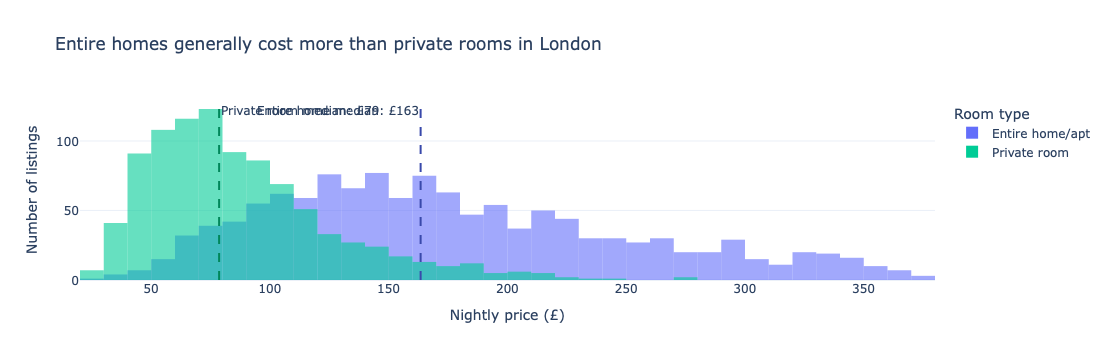

In [7]:
# Task 1: Histogram of price by room type

# Keep only the two required room types
room_df = df_cap[
    df_cap['room_type'].isin(['Entire home/apt', 'Private room'])
].copy()

# Calculate the median price for each room type
medians = room_df.groupby('room_type')['price'].median()

# Create the overlapping histogram
fig = px.histogram(
    room_df,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=40,
    color_discrete_map={
        'Entire home/apt': '#636EFA',
        'Private room': '#00CC96'
    },
    title='Entire homes generally cost more than private rooms in London',
    labels={
        'price': 'Nightly price (£)',
        'count': 'Number of listings',
        'room_type': 'Room type'
    }
)

# Add a separate median reference line for each room type
fig.add_vline(
    x=medians['Entire home/apt'],
    line_color='#3949AB',
    line_dash='dash',
    annotation_text=f"Entire home median: £{medians['Entire home/apt']:.0f}",
    annotation_position='top left'
)

fig.add_vline(
    x=medians['Private room'],
    line_color='#00875A',
    line_dash='dash',
    annotation_text=f"Private room median: £{medians['Private room']:.0f}",
    annotation_position='top right'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Nightly price (£)',
    yaxis_title='Number of listings',
    legend_title='Room type'
)

fig.show()


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

In [8]:
print(df.columns.tolist())

['neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'reviews_per_month']


Two most active boroughs: ['Tower Hamlets', 'Hackney']


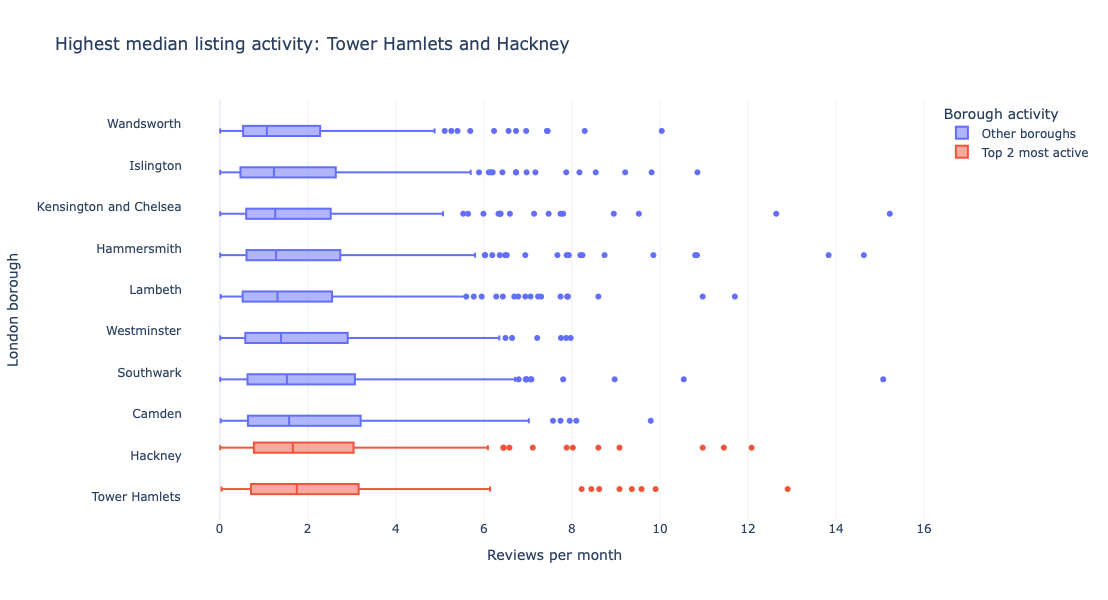

In [9]:
# Task 2: Listing activity by borough

# Keep listings with positive reviews per month
activity_df = df[
    (df['reviews_per_month'] > 0) &
    (df['neighbourhood'].notna())
].copy()

# Calculate the median activity for each borough
borough_medians = (
    activity_df.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

# Identify the two most active boroughs by median
top_two = borough_medians.head(2).index.tolist()

print("Two most active boroughs:", top_two)

# Sort boroughs by median activity, with the most active at the top
borough_order = borough_medians.sort_values(ascending=True).index.tolist()

# Assign colours to highlight the two most active boroughs
activity_df['activity_group'] = activity_df['neighbourhood'].apply(
    lambda borough: 'Top 2 most active' if borough in top_two
    else 'Other boroughs'
)

# Create a horizontal box plot
fig = px.box(
    activity_df,
    x='reviews_per_month',
    y='neighbourhood',
    color='activity_group',
    category_orders={'neighbourhood': borough_order},
    color_discrete_map={
        'Top 2 most active': '#EF553B',
        'Other boroughs': '#636EFA'
    },
    points='outliers',
    title=f"Highest median listing activity: {top_two[0]} and {top_two[1]}",
    labels={
        'reviews_per_month': 'Reviews per month',
        'neighbourhood': 'London borough',
        'activity_group': 'Activity group'
    }
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Reviews per month',
    yaxis_title='London borough',
    legend_title='Borough activity',
    height=max(600, len(borough_order) * 25)
)

fig.show()